In [1]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from IPython.display import HTML
import copernicusmarine
import cartopy
from matplotlib import pyplot as plt
from cartopy.io.img_tiles import OSM
import os
#import pygmt
import cartopy.crs as ccrs
from cartopy.io.img_tiles import OSM
import numpy as np
import math
from datetime import timedelta
from operator import attrgetter


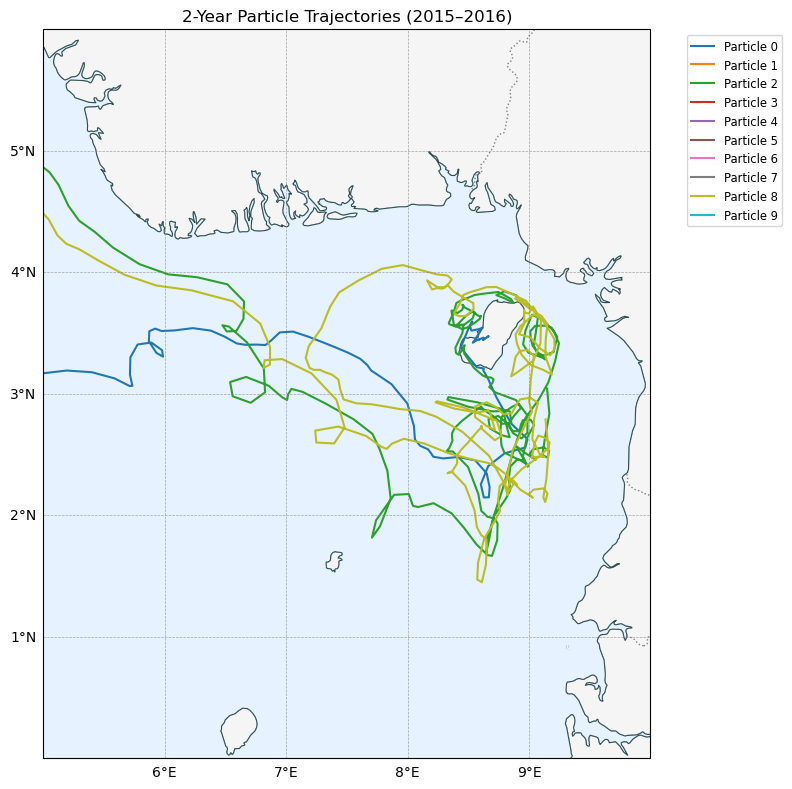

In [2]:
# First check of the output
# 1. Load our completed trajectory output zarr store
output_path = 'CurrentParticles_2years.parquet.zarr'
ds = xr.open_zarr(output_path)

#print("Trajectory dataset loaded successfully!")
#print(ds)
# 2. Set up the map figure
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

for i in range(ds.dims['trajectory']):
    plt.plot(ds.lon.isel(trajectory=i), ds.lat.isel(trajectory=i), label=f'Particle {i}')
# 2. Quick plot of particle trajectories (Longitude vs Latitude)
#plt.figure(figsize=(10, 6))


# 3. Set map extent using our exact area_bounds [North, West, South, East] -> [West, East, South, North]
# area_bounds = [27.04, -43.15, -23.41, 21.36]
ax.set_extent([5, 10, 0, 6], crs=ccrs.PlateCarree())

# 4. Add map features
ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='black', linewidth=0.7)
ax.add_feature(cfeature.OCEAN, facecolor='#e6f2ff')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='darkslategray')
ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='gray')

# 5. Add gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False

plt.title('2-Year Particle Trajectories (2015–2016)')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.show()

In [3]:
ds

<xarray.Dataset>
Dimensions:     (trajectory: 10, obs: 730)
Coordinates:
  * obs         (obs) int32 0 1 2 3 4 5 6 7 ... 722 723 724 725 726 727 728 729
  * trajectory  (trajectory) int64 60 61 62 63 64 65 66 67 68 69
Data variables:
    lat         (trajectory, obs) float32 dask.array<chunksize=(10, 1), meta=np.ndarray>
    lon         (trajectory, obs) float32 dask.array<chunksize=(10, 1), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] dask.array<chunksize=(10, 1), meta=np.ndarray>
    z           (trajectory, obs) float32 dask.array<chunksize=(10, 1), meta=np.ndarray>
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        JITParticleAdvectionRK4DeleteOutOfBounds
    parcels_mesh:           spherical
    parcels_version:        3.1.4

In [4]:
ds2= xr.open_dataset('vel_subset2.nc')
ds2

<xarray.Dataset>
Dimensions:    (time: 731, depth: 50, latitude: 605, longitude: 774)
Coordinates:
  * depth      (depth) float32 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 -23.33 -23.25 -23.17 ... 26.83 26.92 27.0
  * longitude  (longitude) float32 -43.08 -43.0 -42.92 ... 21.17 21.25 21.33
  * time       (time) datetime64[ns] 2015-01-01 2015-01-02 ... 2016-12-31
Data variables:
    uo         (time, depth, latitude, longitude) float32 ...
    vo         (time, depth, latitude, longitude) float32 ...
    thetao     (time, depth, latitude, longitude) float32 ...
    zos        (time, latitude, longitude) float32 ...
    mlotst     (time, latitude, longitude) float32 ...
Attributes:
    references:   http://www.mercator-ocean.fr
    source:       MERCATOR GLORYS12V1
    title:        daily mean fields from Global Ocean Physics Analysis and Fo...
    comment:      CMEMS product
    institution:  MERCATOR OCEAN
    history:      2023/06/01 16:20:05 MERCATOR OCEAN Netcdf creation
    Conventions:  CF-1.4

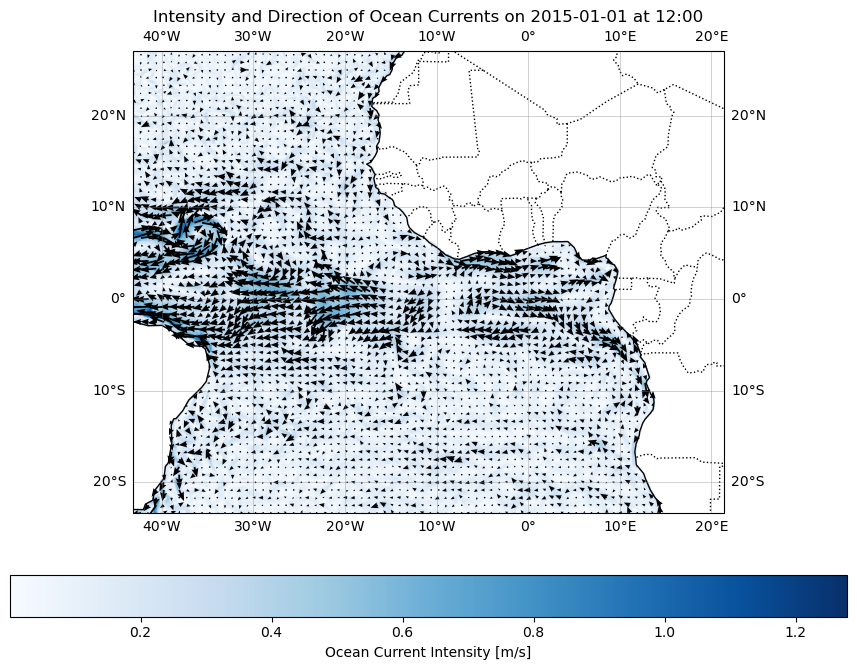

In [20]:

# 1. Select surface data (specifying both time and depth=0 to avoid dimension errors)
ds_surface = ds2.sel(
    time="2015-02-01T12:00:00", depth=0.0, method='nearest'
)

u = ds_surface.uo.values
v = ds_surface.vo.values

# 2. Calculate the current intensity magnitude
intensity = np.sqrt(u**2 + v**2)

# 3. Configure the map parameters
width_inch = 18
height_inch = 8

fig, ax = plt.subplots(
    figsize=(width_inch, height_inch),
    subplot_kw={'projection': ccrs.PlateCarree()},
)

# Convert 1D coordinates to a 2D meshgrid
lon, lat = np.meshgrid(ds_surface.longitude.values, ds_surface.latitude.values)

# Use pcolormesh to display current intensity as the background field
im = ax.pcolormesh(lon, lat, intensity, cmap='Blues', shading='auto')

# Adjust arrow scaling for the quiver plot
scale_factor = 0.1  # Adjust this if arrows are too big or small
u_scaled = u * scale_factor
v_scaled = v * scale_factor

# Skip indices (e.g., every 10th grid point) to prevent arrow clutter
skip = (slice(None, None, 10), slice(None, None, 10))

# Plot velocity vectors with quiver
ax.quiver(
    lon[skip],
    lat[skip],
    u_scaled[skip],
    v_scaled[skip],
    color='black',
    scale=2,
    width=0.003,
    headwidth=4,
)

# Add geographic boundaries and gridlines
ax.coastlines()
ax.add_feature(cartopy.feature.BORDERS, linestyle=':')
ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5)

# Add colorbar for intensity
cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.1, shrink=0.6)
cbar.set_label('Ocean Current Intensity [m/s]')

plt.title('Intensity and Direction of Ocean Currents on 2015-01-01 at 12:00')
plt.show()

In [11]:


# 1. Load your completed trajectory output zarr store
output_path = 'CurrentParticles_2years.parquet.zarr'
ds = xr.open_zarr(output_path)

# Convert xarray dataset to a tidy DataFrame for animation plotting
df = ds.to_dataframe().reset_index()
# Map standard Parcels names ('lon', 'lat', 'time', 'trajectory') to your plotting variables
df = df.rename(columns={'lon': 'x', 'lat': 'y', 'time': 't', 'trajectory': 'particle_id'})

# 2. Set up the map figure
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# 3. Set map extent using your exact area_bounds [North, West, South, East] -> [West, East, South, North]
# area_bounds = [27.04, -43.15, -23.41, 21.36]
ax.set_extent([5, 10, 0, 6], crs=ccrs.PlateCarree())

# 4. Add map features
ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='black', linewidth=0.7)
ax.add_feature(cfeature.OCEAN, facecolor='#e6f2ff')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='darkslategray')
ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='gray')

# 5. Add gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False

# 6. Initialize scatter plot for particle positions
scat = ax.scatter(
    [], [],
    c=[],
    cmap='plasma',
    s=80,
    edgecolors='black',
    linewidth=1.0,
    transform=ccrs.PlateCarree(),
    zorder=5
)
title_text = ax.set_title('', fontsize=13, fontweight='bold', pad=15)

timestamps = sorted(df['t'].unique())

# 7. Animation update function
def update(frame_time):
    # Filter data for the current timestamp frame
    frame_data = df[df['t'] == frame_time]

    # Update marker positions and colors
    scat.set_offsets(frame_data[['x', 'y']].values)
    scat.set_array(frame_data['particle_id'])

    date_str = pd.to_datetime(frame_time).strftime("%Y-%m-%d")
    title_text.set_text(f'2-Year Particle Trajectories\nDate: {date_str}')
    return scat,

# 8. Create the animation (stepping every 10 days for smooth rendering)
ani = animation.FuncAnimation(
    fig,
    update,
    frames=timestamps[::10],
    interval=200,
    blit=False
)

plt.close(fig)

# 9. Render the interactive video player inside JupyterHub
HTML(ani.to_jshtml())

In [2]:
vel_subset2= xr.open_dataset("vel_subset2.nc")
vel_subset2

<xarray.Dataset>
Dimensions:    (time: 731, depth: 50, latitude: 605, longitude: 774)
Coordinates:
  * depth      (depth) float32 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 -23.33 -23.25 -23.17 ... 26.83 26.92 27.0
  * longitude  (longitude) float32 -43.08 -43.0 -42.92 ... 21.17 21.25 21.33
  * time       (time) datetime64[ns] 2015-01-01 2015-01-02 ... 2016-12-31
Data variables:
    uo         (time, depth, latitude, longitude) float32 ...
    vo         (time, depth, latitude, longitude) float32 ...
    thetao     (time, depth, latitude, longitude) float32 ...
    zos        (time, latitude, longitude) float32 ...
    mlotst     (time, latitude, longitude) float32 ...
Attributes:
    references:   http://www.mercator-ocean.fr
    source:       MERCATOR GLORYS12V1
    title:        daily mean fields from Global Ocean Physics Analysis and Fo...
    comment:      CMEMS product
    institution:  MERCATOR OCEAN
    history:      2023/06/01 16:20:05 MERCATOR OCEAN Netcdf creation
    Conventions:  CF-1.4

In [8]:

# 1. Load your new 3-site trajectory output zarr store
output_path = 'CurrentParticles_3Sites_2years.parquet.zarr'
ds3 = xr.open_zarr(output_path)

# Convert xarray dataset to a tidy DataFrame for animation plotting
df = ds3.to_dataframe().reset_index()
df = df.rename(columns={'lon': 'x', 'lat': 'y', 'time': 't', 'trajectory': 'particle_id'})

# 2. Set up the map figure
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# 3. Set map extent using your exact area bounds [West, East, South, North]
ax.set_extent([-43.15, 21.36, -23.41, 27.04], crs=ccrs.PlateCarree())

# 4. Add map features
ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='black', linewidth=0.7)
ax.add_feature(cfeature.OCEAN, facecolor='#e6f2ff')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='darkslategray')
ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='gray')

# 5. Add gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False

# 6. Initialize scatter plot for particle positions (colored by particle ID / release group)
scat = ax.scatter(
    [], [],
    c=[],
    cmap='viridis',
    s=70,
    edgecolors='black',
    linewidth=0.8,
    transform=ccrs.PlateCarree(),
    zorder=5
)
title_text = ax.set_title('', fontsize=13, fontweight='bold', pad=15)

timestamps = sorted(df['t'].unique())

# 7. Animation update function
def update(frame_time):
    frame_data = df[df['t'] == frame_time]

    scat.set_offsets(frame_data[['x', 'y']].values)
    scat.set_array(frame_data['particle_id'])

    date_str = pd.to_datetime(frame_time).strftime("%Y-%m-%d")
    title_text.set_text(f'Multi-Site 2-Year Particle Dispersal\nDate: {date_str}')
    return scat,

# 8. Create the animation
ani = animation.FuncAnimation(
    fig,
    update,
    frames=timestamps[::10],  # Step every 10 days
    interval=200,
    blit=False
)

plt.close(fig)

# 9. Render the interactive video player
HTML(ani.to_jshtml())

In [10]:
from datetime import timedelta
import numpy as np
import xarray as xr
from parcels import (
    AdvectionRK4,
    FieldSet,
    JITParticle,
    ParticleSet,
    StatusCode,
)

# 1. Open dataset to get the full spatial coordinates
ds2 = xr.open_dataset('vel_subset2.nc')

# 2. Setup FieldSet
filenames = {'U': 'vel_subset2.nc', 'V': 'vel_subset2.nc'}
variables = {'U': 'uo', 'V': 'vo'}
dimensions = {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'}
fieldset = FieldSet.from_netcdf(filenames, variables, dimensions)

# 3. Create a region-wide grid (subsampling every 15th grid point to keep particle count manageable)
lon_vals = ds2.longitude.values[::15]
lat_vals = ds2.latitude.values[::15]
lon_g, lat_g = np.meshgrid(lon_vals, lat_vals)

lons = lon_g.flatten()
lats = lat_g.flatten()
depths = np.full(lons.shape, 0.5, dtype=np.float32)

# 4. Initialize ParticleSet across the full domain
pset = ParticleSet.from_list(
    fieldset=fieldset,
    pclass=JITParticle,
    lon=lons,
    lat=lats,
    depth=depths,
    time=0,
)


# 5. Define out-of-bounds error handling
def DeleteOutOfBounds(particle, fieldset, time):
  if particle.state == StatusCode.ErrorOutOfBounds:
    particle.delete()


# 6. Run simulation
pset.execute(
    [AdvectionRK4, DeleteOutOfBounds],
    runtime=timedelta(days=30),
    dt=timedelta(hours=1),
    output_file=pset.ParticleFile(
        name='basin_particles.zarr', outputdt=timedelta(days=1)
    ),
)

INFO: Output files are stored in basin_particles.zarr.
100%|██████████| 2592000.0/2592000.0 [00:40<00:00, 63345.45it/s]


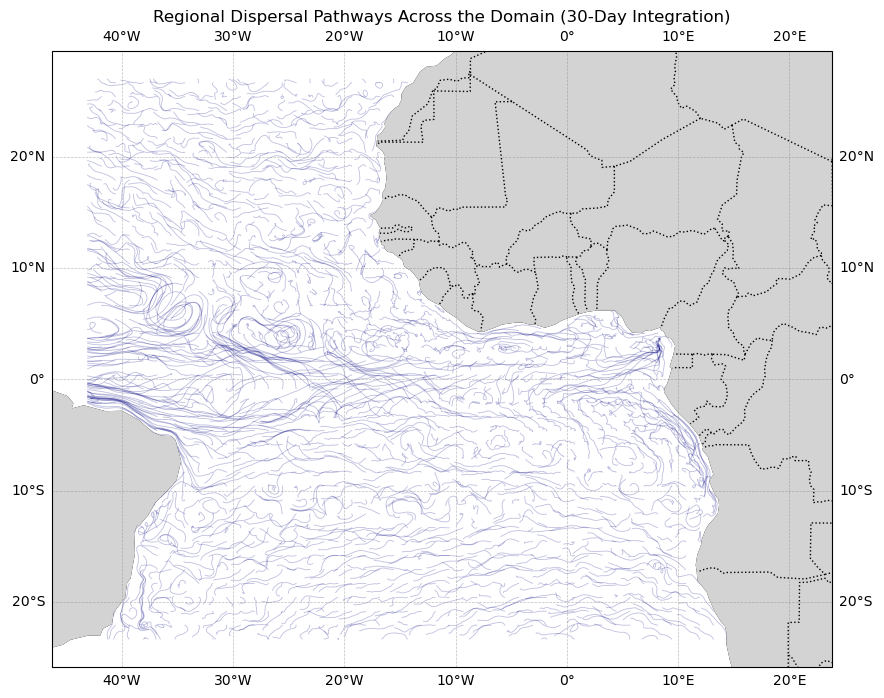

In [11]:
import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt
import xarray as xr

# Load the basin-wide particle output
ds_particles = xr.open_dataset('basin_particles.zarr', engine='zarr')

fig, ax = plt.subplots(
    figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()}
)

# Loop through trajectories and plot their paths
num_traj = ds_particles.dims['trajectory']
for i in range(num_traj):
  ax.plot(
      ds_particles.lon.values[i, :],
      ds_particles.lat.values[i, :],
      color='navy',
      alpha=0.25,
      linewidth=0.6,
      transform=ccrs.PlateCarree(),
  )

# Cartography features
ax.coastlines()
ax.add_feature(cartopy.feature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cartopy.feature.BORDERS, linestyle=':', zorder=2)
ax.gridlines(
    draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--'
)

plt.title('Regional Dispersal Pathways Across the Domain (30-Day Integration)')
plt.show()

INFO: Output files are stored in basin_particles.zarr.
100%|██████████| 2592000.0/2592000.0 [00:46<00:00, 55313.46it/s]


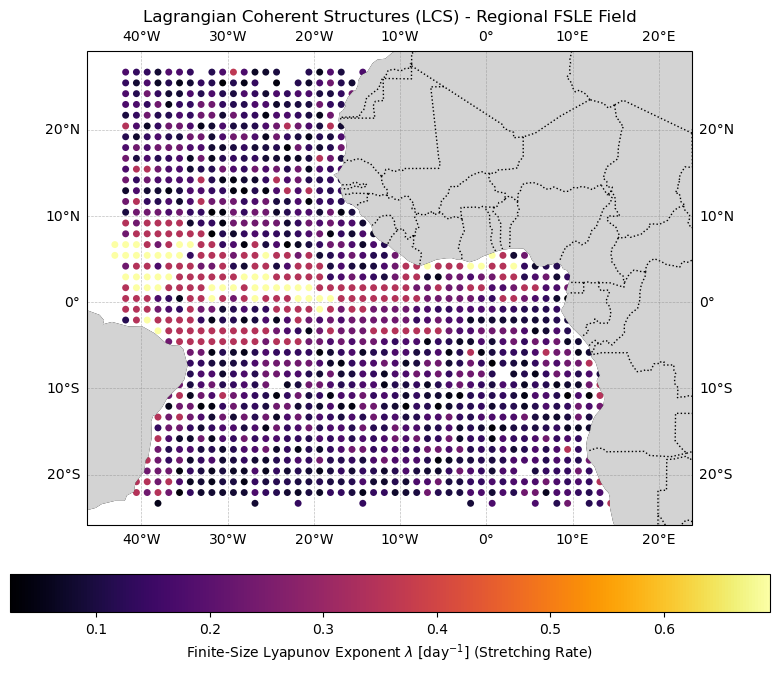

In [14]:
from datetime import timedelta
import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from parcels import (
    AdvectionRK4,
    FieldSet,
    JITParticle,
    ParticleSet,
    StatusCode,
)

# ==========================================
# PART 1: BASIN-WIDE PARTICLE SIMULATION
# ==========================================

# 1. Open dataset to get spatial coordinates
ds2 = xr.open_dataset('vel_subset2.nc')

# 2. Setup FieldSet from GLORYS velocities
filenames = {'U': 'vel_subset2.nc', 'V': 'vel_subset2.nc'}
variables = {'U': 'uo', 'V': 'vo'}
dimensions = {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'}
fieldset = FieldSet.from_netcdf(filenames, variables, dimensions)

# 3. Create a region-wide grid (subsampled to keep particle count manageable)
lon_vals = ds2.longitude.values[::15]
lat_vals = ds2.latitude.values[::15]
lon_g, lat_g = np.meshgrid(lon_vals, lat_vals)

lons = lon_g.flatten()
lats = lat_g.flatten()
depths = np.full(lons.shape, 0.5, dtype=np.float32)

# 4. Initialize ParticleSet across the full domain
pset = ParticleSet.from_list(
    fieldset=fieldset,
    pclass=JITParticle,
    lon=lons,
    lat=lats,
    depth=depths,
    time=0,
)


# 5. Define out-of-bounds error handling kernel
def DeleteOutOfBounds(particle, fieldset, time):
  if particle.state == StatusCode.ErrorOutOfBounds:
    particle.delete()


# 6. Execute simulation
pset.execute(
    [AdvectionRK4, DeleteOutOfBounds],
    runtime=timedelta(days=30),
    dt=timedelta(hours=1),
    output_file=pset.ParticleFile(
        name='basin_particles.zarr', outputdt=timedelta(days=1)
    ),
)


# ==========================================
# PART 2: POST-PROCESSING & LCS (FSLE) PLOTTING
# ==========================================

# 1. Open the particle tracking output
ds_particles = xr.open_dataset('basin_particles.zarr', engine='zarr')

lons_traj = ds_particles.lon.values  # Shape: (num_particles, num_times)
lats_traj = ds_particles.lat.values  # Shape: (num_particles, num_times)
num_particles = lons_traj.shape[0]

# 2. Define separation thresholds
d0 = 0.2  # Initial separation distance threshold (degrees)
factor = 2.0  # Expansion factor
df = d0 * factor

# 3. Calculate separation times safely with scalar conversion
time_data = ds_particles.time.values
if time_data.ndim == 2:
  time_days_matrix = (time_data - time_data[:, 0:1]) / np.timedelta64(1, 'D')
else:
  time_days_matrix = (time_data - time_data[0]) / np.timedelta64(1, 'D')

tau = np.full(num_particles, np.nan)

for i in range(num_particles):
  dist = np.sqrt(
      (lons_traj[i, :] - lons_traj[i, 0]) ** 2
      + (lats_traj[i, :] - lats_traj[i, 0]) ** 2
  )
  idx_exceed = np.where(dist >= df)[0]

  if len(idx_exceed) > 0:
    if time_days_matrix.ndim == 2:
      t_raw = time_days_matrix[i, idx_exceed[0]]
    else:
      t_raw = time_days_matrix[idx_exceed[0]]

    t_val = float(np.ravel(t_raw)[0])

    if t_val > 0:
      tau[i] = (1.0 / t_val) * np.log(factor)

# Get initial positions for mapping
lon_init = lons_traj[:, 0]
lat_init = lats_traj[:, 0]

# 4. Render the LCS / Lyapunov Exponent Map via Cartopy
fig, ax = plt.subplots(
    figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()}
)

sc = ax.scatter(
    lon_init,
    lat_init,
    c=tau,
    cmap='inferno',
    s=25,
    transform=ccrs.PlateCarree(),
    edgecolors='none',
)

ax.coastlines()
ax.add_feature(cartopy.feature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cartopy.feature.BORDERS, linestyle=':', zorder=2)
ax.gridlines(
    draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--'
)

cbar = plt.colorbar(sc, ax=ax, orientation='horizontal', pad=0.08, shrink=0.7)
cbar.set_label(
    'Finite-Size Lyapunov Exponent $\lambda$ [day$^{-1}$] (Stretching Rate)'
)

plt.title('Lagrangian Coherent Structures (LCS) - Regional FSLE Field')
plt.show()

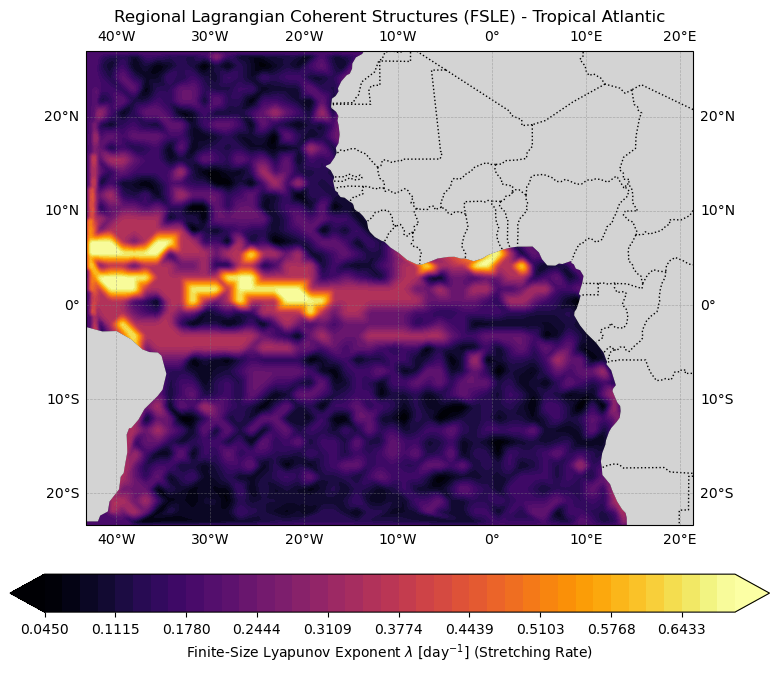

In [18]:
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

# 1. Open the particle tracking output
ds_particles = xr.open_dataset('basin_particles.zarr', engine='zarr')

lons_traj = ds_particles.lon.values  # Shape: (num_particles, num_times)
lats_traj = ds_particles.lat.values  # Shape: (num_particles, num_times)
num_particles = lons_traj.shape[0]

# 2. Define separation thresholds
d0 = 0.2  # Initial separation distance threshold (degrees)
factor = 2.0  # Expansion factor
df = d0 * factor

# 3. Calculate separation times safely
time_data = ds_particles.time.values
if time_data.ndim == 2:
  time_days_matrix = (time_data - time_data[:, 0:1]) / np.timedelta64(1, 'D')
else:
  time_days_matrix = (time_data - time_data[0]) / np.timedelta64(1, 'D')

tau = np.full(num_particles, np.nan)

for i in range(num_particles):
  dist = np.sqrt(
      (lons_traj[i, :] - lons_traj[i, 0]) ** 2
      + (lats_traj[i, :] - lats_traj[i, 0]) ** 2
  )
  idx_exceed = np.where(dist >= df)[0]

  if len(idx_exceed) > 0:
    if time_days_matrix.ndim == 2:
      t_raw = time_days_matrix[i, idx_exceed[0]]
    else:
      t_raw = time_days_matrix[idx_exceed[0]]

    t_val = float(np.ravel(t_raw)[0])

    if t_val > 0:
      tau[i] = (1.0 / t_val) * np.log(factor)

# Get initial positions
lon_init = lons_traj[:, 0]
lat_init = lats_traj[:, 0]

# Filter out NaNs for clean interpolation
valid = ~np.isnan(tau)
lon_v, lat_v, tau_v = lon_init[valid], lat_init[valid], tau[valid]

# 4. Create a regular grid strictly bounded by your domain limits:
# area_bounds = [27.04 (North), -43.15 (West), -23.41 (South), 21.36 (East)]
grid_lon = np.linspace(-43.15, 21.36, 300)
grid_lat = np.linspace(-23.41, 27.04, 300)
GX, GY = np.meshgrid(grid_lon, grid_lat)

# Interpolate scattered values onto the regional grid
GTau = griddata((lon_v, lat_v), tau_v, (GX, GY), method='linear')
GTau_smooth = gaussian_filter(
    np.nan_to_num(GTau, nan=np.nanmean(tau_v)), sigma=1.0
)

# 5. Render the Regional LCS Map
fig, ax = plt.subplots(
    figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()}
)

# Explicitly set bounds to your exact study domain
ax.set_extent([-43.15, 21.36, -23.41, 27.04], crs=ccrs.PlateCarree())

# Plot contours of the Lyapunov stretching field
levels = np.linspace(np.nanmin(GTau_smooth), np.nanmax(GTau_smooth), 40)
cs = ax.contourf(
    GX,
    GY,
    GTau_smooth,
    levels=levels,
    cmap='inferno',
    extend='both',
    transform=ccrs.PlateCarree(),
)

# Cartography features
ax.coastlines(resolution='110m', color='black', linewidth=0.8)
ax.add_feature(cartopy.feature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cartopy.feature.BORDERS, linestyle=':', zorder=2)
ax.gridlines(
    draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--'
)

# Colorbar and layout
cbar = plt.colorbar(cs, ax=ax, orientation='horizontal', pad=0.08, shrink=0.7)
cbar.set_label(
    'Finite-Size Lyapunov Exponent $\lambda$ [day$^{-1}$] (Stretching Rate)'
)

plt.title('Regional Lagrangian Coherent Structures (FSLE) - Tropical Atlantic')
plt.show()

INFO: Output files are stored in dense_particles.zarr.
100%|██████████| 2592000.0/2592000.0 [01:01<00:00, 41831.51it/s]


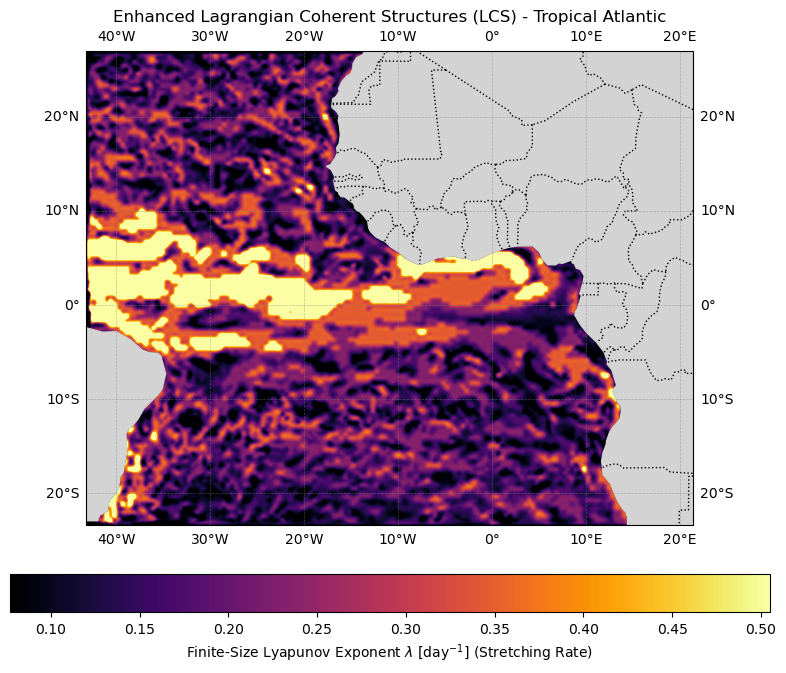

In [19]:
from datetime import timedelta
import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter, sobel
import xarray as xr
from parcels import (
    AdvectionRK4,
    FieldSet,
    JITParticle,
    ParticleSet,
    StatusCode,
)

# ==========================================
# 1. HIGH-DENSITY SIMULATION (Fine step size)
# ==========================================
ds2 = xr.open_dataset('vel_subset2.nc')

filenames = {'U': 'vel_subset2.nc', 'V': 'vel_subset2.nc'}
variables = {'U': 'uo', 'V': 'vo'}
dimensions = {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'}
fieldset = FieldSet.from_netcdf(filenames, variables, dimensions)

# Increase density by changing stride from 15 to 5 for sharper structures
lon_vals = ds2.longitude.values[::5]
lat_vals = ds2.latitude.values[::5]
lon_g, lat_g = np.meshgrid(lon_vals, lat_vals)

lons = lon_g.flatten()
lats = lat_g.flatten()
depths = np.full(lons.shape, 0.5, dtype=np.float32)

pset = ParticleSet.from_list(
    fieldset=fieldset,
    pclass=JITParticle,
    lon=lons,
    lat=lats,
    depth=depths,
    time=0,
)


def DeleteOutOfBounds(particle, fieldset, time):
  if particle.state == StatusCode.ErrorOutOfBounds:
    particle.delete()


pset.execute(
    [AdvectionRK4, DeleteOutOfBounds],
    runtime=timedelta(days=30),
    dt=timedelta(hours=1),
    output_file=pset.ParticleFile(
        name='dense_particles.zarr', outputdt=timedelta(days=1)
    ),
)

# ==========================================
# 2. HIGH-RESOLUTION FSLE & RIDGE ENHANCEMENT
# ==========================================
ds_particles = xr.open_dataset('dense_particles.zarr', engine='zarr')
lons_traj = ds_particles.lon.values
lats_traj = ds_particles.lat.values
num_particles = lons_traj.shape[0]

d0 = 0.15
factor = 2.0
df = d0 * factor

time_data = ds_particles.time.values
time_days_matrix = (
    (time_data - time_data[:, 0:1]) / np.timedelta64(1, 'D')
    if time_data.ndim == 2
    else (time_data - time_data[0]) / np.timedelta64(1, 'D')
)

tau = np.full(num_particles, np.nan)
for i in range(num_particles):
  dist = np.sqrt(
      (lons_traj[i, :] - lons_traj[i, 0]) ** 2
      + (lats_traj[i, :] - lats_traj[i, 0]) ** 2
  )
  idx_exceed = np.where(dist >= df)[0]
  if len(idx_exceed) > 0:
    t_raw = (
        time_days_matrix[i, idx_exceed[0]]
        if time_days_matrix.ndim == 2
        else time_days_matrix[idx_exceed[0]]
    )
    t_val = float(np.ravel(t_raw)[0])
    if t_val > 0:
      tau[i] = (1.0 / t_val) * np.log(factor)

lon_init = lons_traj[:, 0]
lat_init = lats_traj[:, 0]
valid = ~np.isnan(tau)
lon_v, lat_v, tau_v = lon_init[valid], lat_init[valid], tau[valid]

# Fine grid mesh for structural clarity
grid_lon = np.linspace(-43.15, 21.36, 500)
grid_lat = np.linspace(-23.41, 27.04, 500)
GX, GY = np.meshgrid(grid_lon, grid_lat)

GTau = griddata((lon_v, lat_v), tau_v, (GX, GY), method='cubic')
GTau_clean = np.nan_to_num(GTau, nan=np.nanpercentile(tau_v, 5))
GTau_smooth = gaussian_filter(GTau_clean, sigma=0.8)

# ==========================================
# 3. PUBLICATION-GRADE PLOTTING
# ==========================================
fig, ax = plt.subplots(
    figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()}
)
ax.set_extent([-43.15, 21.36, -23.41, 27.04], crs=ccrs.PlateCarree())

# Clip color bounds (vmin/vmax) to filter out extreme equatorial noise
# and enhance contrast for off-equatorial ridges
vmin = np.nanpercentile(GTau_smooth, 10)
vmax = np.nanpercentile(GTau_smooth, 90)

im = ax.imshow(
    GTau_smooth,
    extent=[-43.15, 21.36, -23.41, 27.04],
    origin='lower',
    cmap='inferno',
    vmin=vmin,
    vmax=vmax,
    transform=ccrs.PlateCarree(),
    interpolation='bicubic',
)

ax.coastlines(resolution='110m', color='black', linewidth=0.8)
ax.add_feature(cartopy.feature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cartopy.feature.BORDERS, linestyle=':', zorder=2)
ax.gridlines(
    draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--'
)

cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.08, shrink=0.7)
cbar.set_label(
    'Finite-Size Lyapunov Exponent $\lambda$ [day$^{-1}$] (Stretching Rate)'
)

plt.title(
    'Enhanced Lagrangian Coherent Structures (LCS) - Tropical Atlantic'
)
plt.show()